# MNIST classification with a NumPy neural network

This notebook loads handwritten digit images, prepares training and evaluation sets, displays a sample, and trains the neural network implemented in `neural_network.py`.

## 1. Imports and plot display

NumPy provides the arrays and numerical operations. `fetch_openml` loads MNIST, while Matplotlib displays the sample image. `%matplotlib inline` renders the plot inside the notebook.

In [31]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

## 2. Load and normalize MNIST

MNIST contains 70,000 grayscale images, each stored as a row of 784 pixel values (28 × 28). The pixel array is converted to `float32` and divided by 255, placing its values between 0 and 1. The labels are converted to integers representing digits 0 through 9. The printed shapes confirm the number of images and labels.

In [32]:
X, y = fetch_openml(
    "mnist_784", version=1, return_X_y=True, as_frame=False
)
X = X.astype(np.float32) / 255.0
y = y.astype(np.int64)

print("Images:", X.shape)
print("Labels:", y.shape)

Images: (70000, 784)
Labels: (70000,)


## 3. Split the dataset

The first 60,000 MNIST images form the original training set, and the last 10,000 form the test set. A seeded permutation selects 5,000 of the original training images for validation, leaving 55,000 for training. Validation measures performance during development; the separate test set is evaluated after training. The printed shapes show the size of each split.

In [33]:
X_train_all, X_test = X[:60_000], X[60_000:]
y_train_all, y_test = y[:60_000], y[60_000:]

rng = np.random.default_rng(42)
order = rng.permutation(len(X_train_all))
validation_indices = order[:5_000]
train_indices = order[5_000:]

X_train = X_train_all[train_indices]
y_train = y_train_all[train_indices]
X_validation = X_train_all[validation_indices]
y_validation = y_train_all[validation_indices]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (55000, 784) (55000,)
Validation: (5000, 784) (5000,)
Test: (10000, 784) (10000,)


## 4. Inspect training images

The first nine training samples are shown in a 3 × 3 grid. Each 784-value vector is reshaped to a 28 × 28 image, and the title gives its digit label.

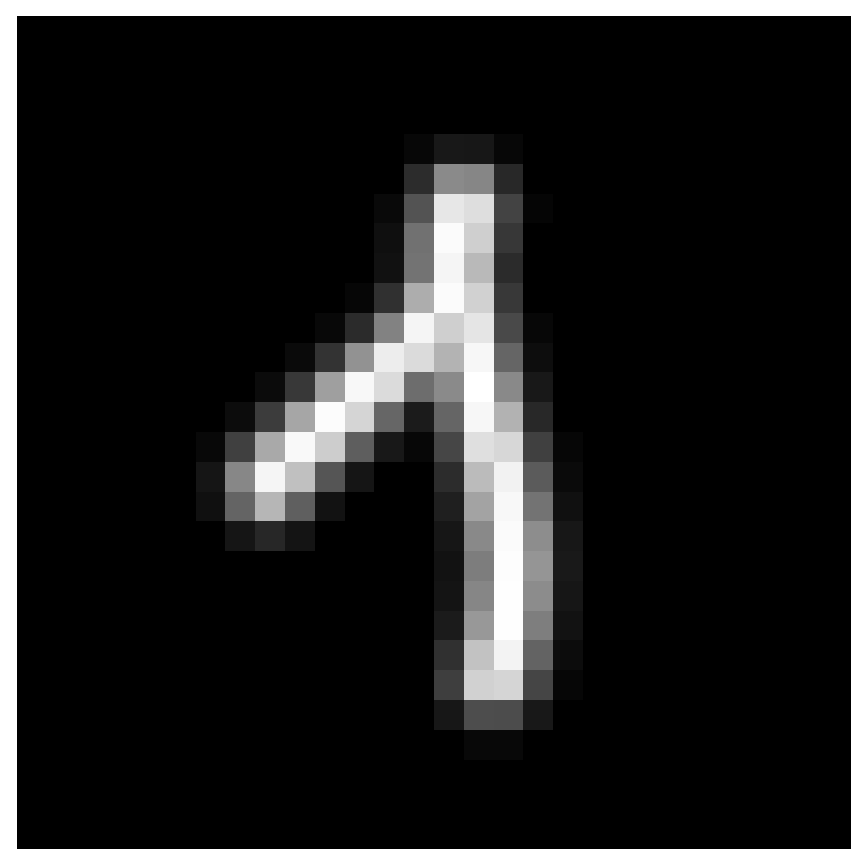

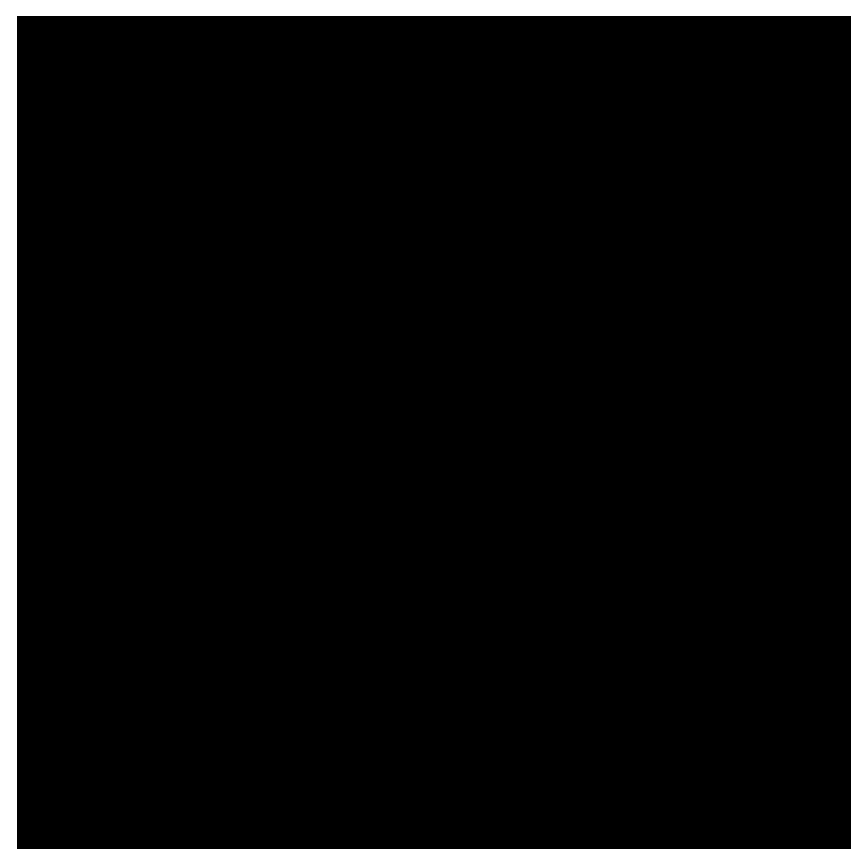

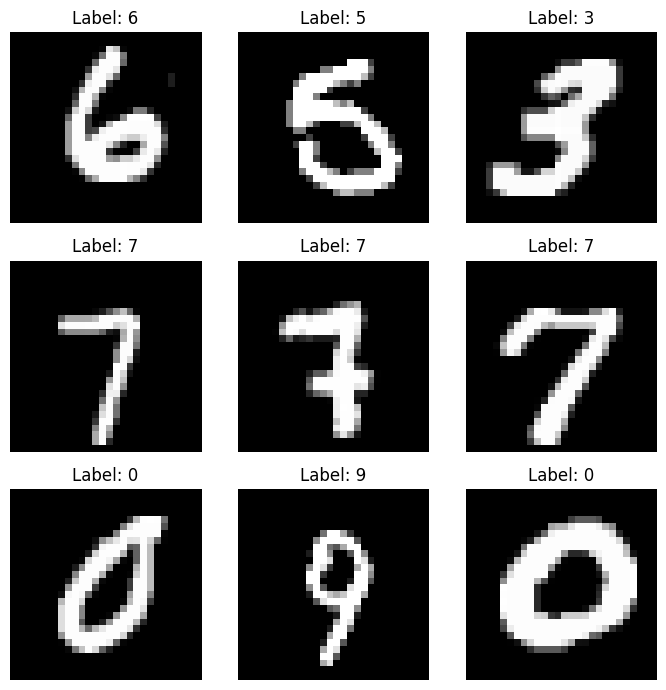

In [34]:
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for ax, image, label in zip(axes.flat, X_train[:9], y_train[:9]):
    ax.imshow(image.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {label}")
    ax.axis("off")

fig.tight_layout()
plt.show()

## 5. Augment training images

Each training batch gets small random rotations (up to 12 degrees), shifts (up to 2 pixels), and scaling (0.9 to 1.1) on about half its images. The other half keeps its original pixels. Labels stay the same. Validation and test images are never augmented.

In [35]:
from scipy import ndimage as ndi

def augment_batch(batch, rng):
    augmented = batch.reshape(-1, 28, 28).copy()
    center = np.array([13.5, 13.5])
    for i in range(len(augmented)):
        if rng.random() >= 0.5:
            continue
        angle = np.deg2rad(rng.uniform(-12, 12))
        scale = rng.uniform(0.9, 1.1)
        translation = rng.uniform(-2, 2, size=2)
        cosine, sine = np.cos(angle), np.sin(angle)
        matrix = np.array([[cosine, -sine], [sine, cosine]]) / scale
        offset = center - matrix @ (center + translation)
        augmented[i] = ndi.affine_transform(
            augmented[i], matrix, offset=offset, output_shape=(28, 28),
            order=1, mode="constant", cval=0.0, prefilter=False,
        )
    return np.clip(augmented.reshape(-1, 784), 0, 1)


## 6. Train and evaluate the neural network

`NeuralNetwork` is implemented in `neural_network.py`. Each number in `hidden_layers` sets the width of one hidden ReLU layer: `(128,)` creates one layer, while `(128, 64)` creates two. Training applies the augmentation above to batches only; validation and test sets retain their original pixels. Each epoch reports training loss and validation accuracy, and the final lines report test accuracy.

In [36]:
import importlib
import neural_network

# Reload edits to neural_network.py without restarting the notebook kernel.
NeuralNetwork = importlib.reload(neural_network).NeuralNetwork

hidden_layers = (128,)
network = NeuralNetwork(
    input_size=X_train.shape[1],
    hidden_layers=hidden_layers,
    output_size=len(np.unique(y_train)),
)
network.train(
    X_train, y_train, epochs=5, batch_size=128, learning_rate=0.1,
    X_validation=X_validation, y_validation=y_validation,
    augment_batch=augment_batch,
)
print(f"Test accuracy: {network.accuracy(X_test, y_test):.2%}")
print(f"First image: prediction={network.predict(X_train[0])[0]}, label={y_train[0]}")

Epoch 1: loss = 0.7863, validation accuracy = 89.74%
Epoch 2: loss = 0.4841, validation accuracy = 92.84%
Epoch 3: loss = 0.3727, validation accuracy = 94.64%
Epoch 4: loss = 0.2975, validation accuracy = 95.40%
Epoch 5: loss = 0.2496, validation accuracy = 96.16%
Test accuracy: 96.61%
First image: prediction=6, label=6


## 7. Draw a digit and predict it

Run the training cell first. Draw a white digit on the black canvas by holding the left mouse button and dragging. Click **Predict** to classify it or **Clear** to start again. Before prediction, the drawing is cropped, resized to fit a 20 x 20 area, and centered by its pixel intensity in a 28 x 28 image. The interactive canvas uses `ipympl`.

In [37]:
%matplotlib widget

import ipywidgets as widgets
from IPython.display import display

def preprocess_drawing(image):
    ink = np.clip(np.asarray(image, dtype=np.float32).reshape(28, 28), 0, 1)
    rows, cols = np.nonzero(ink > 0.08)
    if len(rows) == 0:
        return np.zeros((28, 28), dtype=np.float32)

    crop = ink[rows.min():rows.max() + 1, cols.min():cols.max() + 1]
    crop = crop / crop.max()
    height = max(1, round(crop.shape[0] * 20 / max(crop.shape)))
    width = max(1, round(crop.shape[1] * 20 / max(crop.shape)))
    resized = ndi.zoom(crop, (height / crop.shape[0], width / crop.shape[1]),
                       order=1, prefilter=False)
    centered = np.zeros((28, 28), dtype=np.float32)
    top, left = (28 - height) // 2, (28 - width) // 2
    centered[top:top + height, left:left + width] = resized
    center_of_mass = ndi.center_of_mass(centered)
    shift = (13.5 - center_of_mass[0], 13.5 - center_of_mass[1])
    return ndi.shift(centered, shift, order=1, mode="constant",
                     cval=0.0, prefilter=False).astype(np.float32)

# The visible canvas is enlarged, but its underlying pixels match MNIST.
drawing = np.zeros((28, 28), dtype=np.float32)
with plt.ioff():
    fig, ax = plt.subplots(figsize=(5, 5))
fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
image_artist = ax.imshow(drawing, cmap="gray", vmin=0, vmax=1,
                         interpolation="nearest")
ax.set_xlim(-0.5, 27.5)
ax.set_ylim(27.5, -0.5)
ax.axis("off")
fig.canvas.toolbar_visible = False
fig.canvas.header_visible = False
fig.canvas.footer_visible = False

is_drawing = False
last_point = None
result = widgets.HTML(value="Draw a digit, then click Predict.")
predict_button = widgets.Button(description="Predict", button_style="primary")
clear_button = widgets.Button(description="Clear")

def paint(x, y):
    # A soft, roughly two-pixel-wide brush makes white strokes on black.
    rows, cols = np.ogrid[:28, :28]
    distance_squared = (cols - x) ** 2 + (rows - y) ** 2
    brush = np.exp(-distance_squared / (2 * 0.9 ** 2))
    brush[distance_squared > 2.5 ** 2] = 0
    drawing[:] = np.maximum(drawing, brush.astype(np.float32))
    image_artist.set_data(drawing)
    fig.canvas.draw_idle()

def on_press(event):
    global is_drawing, last_point
    if event.inaxes is ax and event.button == 1:
        is_drawing = True
        last_point = (event.xdata, event.ydata)
        paint(*last_point)
        result.value = ""

def on_move(event):
    global last_point
    if not is_drawing or event.inaxes is not ax or event.xdata is None:
        return
    x, y = event.xdata, event.ydata
    steps = max(1, int(np.ceil(2 * max(abs(x - last_point[0]),
                                        abs(y - last_point[1])))))
    for t in np.linspace(0, 1, steps + 1)[1:]:
        paint(last_point[0] + t * (x - last_point[0]),
              last_point[1] + t * (y - last_point[1]))
    last_point = (x, y)

def on_release(event):
    global is_drawing, last_point
    is_drawing = False
    last_point = None

def predict_digit(_):
    if not drawing.any():
        result.value = "Draw a digit first."
        return
    prepared = preprocess_drawing(drawing)
    digit = int(network.predict(prepared.reshape(1, 784))[0])
    result.value = f"<b>Predicted digit: {digit}</b>"

def clear_drawing(_):
    drawing.fill(0)
    image_artist.set_data(drawing)
    fig.canvas.draw_idle()
    result.value = "Draw a digit, then click Predict."

fig.canvas.mpl_connect("button_press_event", on_press)
fig.canvas.mpl_connect("motion_notify_event", on_move)
fig.canvas.mpl_connect("button_release_event", on_release)
predict_button.on_click(predict_digit)
clear_button.on_click(clear_drawing)
display(widgets.VBox([fig.canvas, widgets.HBox([predict_button, clear_button]), result]))